# Customer Churn Prediction Project

## _A Project by Om Satyawan Pathak_
## _Contact: omsatyawanpathakgit@gmail.com_

In [1]:
#Import the required modules:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import warnings
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, ExtraTreesClassifier
from xgboost import XGBClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import classification_report, confusion_matrix, accuracy_score


warnings.filterwarnings("ignore")

In [2]:
#Import the dataset:
df = pd.read_csv("dataset.csv")

In [3]:
#Inspect the dataset:

print("Null values:")
print(df.isnull().sum())

print("\n\nNo. of duplicate values:")
print(df.duplicated().sum())

print("\n\nCheck the data-types of all columns:")
print(df.dtypes)

print("\n\nView the basic information of the dataset:")
print(df.info())

print("\n\n\nInspect the first 5 rows of the dataset:")
print(df.head())


Null values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


No. of duplicate values:
0


Check the data-types of all columns:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             obj

In [4]:
#Convert the 'TotalCharges' column to numeric-type value:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

#Check for imbalance in the target attribute:
df.Churn.value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [5]:
df.dtypes

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object

In [6]:
#Data Proprocessing:

cols = [
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "MultipleLines"
]

df[cols] = df[cols].replace("No internet service", "No")
df.drop("customerID", axis=1, inplace=True)

# Encode target: No = 0, Yes = 1
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})

print("Shape after cleaning:", df.shape)
display(df.head())


print("Check for imbalance in the target attribute:")
print(df["Churn"].value_counts())

Shape after cleaning: (7043, 20)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


Check for imbalance in the target attribute:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [7]:
#Check for missing values in all columns once again:
df.isnull().sum()

gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [8]:
df["TotalCharges"].fillna(0,inplace=True)

In [9]:
#Machine Learning part:

In [10]:
feature_cols = [
    "gender", "tenure", "Dependents", "SeniorCitizen", "Partner",
    "InternetService", "PhoneService", "TechSupport", "Contract",
    "PaymentMethod", "TotalCharges", "StreamingTV", "StreamingMovies"
]

X = df[feature_cols]
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

num_cols = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = X_train.select_dtypes(include=["object"]).columns.tolist()

print("Numerical columns:", num_cols)
print("Categorical columns:", cat_cols)

Numerical columns: ['tenure', 'SeniorCitizen', 'TotalCharges']
Categorical columns: ['gender', 'Dependents', 'Partner', 'InternetService', 'PhoneService', 'TechSupport', 'Contract', 'PaymentMethod', 'StreamingTV', 'StreamingMovies']


In [11]:
#Preprocess the data manually (without using a pipeline):


#Standard-Scale the numeric columns:
scaler = StandardScaler()
X_train_num = pd.DataFrame(
    scaler.fit_transform(X_train[num_cols]),
    columns=num_cols,
    index=X_train.index
)
X_test_num = pd.DataFrame(
    scaler.transform(X_test[num_cols]),
    columns=num_cols,
    index=X_test.index
)



# One-hot encode categorical columns:
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
X_train_cat_array = encoder.fit_transform(X_train[cat_cols])
X_test_cat_array = encoder.transform(X_test[cat_cols])

cat_feature_names = encoder.get_feature_names_out(cat_cols)

X_train_cat = pd.DataFrame(
    X_train_cat_array, columns=cat_feature_names, index=X_train.index
)
X_test_cat = pd.DataFrame(
    X_test_cat_array, columns=cat_feature_names, index=X_test.index
)

# Combine scaled numerical and encoded categorical features
X_train_processed = pd.concat([X_train_num, X_train_cat], axis=1)
X_test_processed = pd.concat([X_test_num, X_test_cat], axis=1)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (5634, 27)
Processed testing shape: (1409, 27)


In [12]:
#Define the classification models:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "KNN Classifier": KNeighborsClassifier(n_neighbors=8, n_jobs=-1),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=130, max_depth=9, n_jobs=-1, random_state=42
    ),
    "AdaBoost": AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=6),
        n_estimators=200,
        learning_rate=0.8,
        random_state=42
    ),
    "XGBoost": XGBClassifier(
        n_estimators=300,
        learning_rate=0.1,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1,
        tree_method="hist",
        eval_metric="logloss"
    )
}

In [13]:
#Compare all the ml models using Cross-Validation:
kf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
scoring = ["accuracy", "f1_weighted"]

results = []

for name, model in models.items():
    print(f"Running {name}...")

    cv_results = cross_validate(
        model,
        X_train_processed,
        y_train,
        cv=kf,
        scoring=scoring,
        n_jobs=-1
    )

    results.append({
        "Model": name,
        "CV Accuracy": round(np.mean(cv_results["test_accuracy"]), 4),
        "CV F1 Score": round(np.mean(cv_results["test_f1_weighted"]), 4)
    })

results_df = pd.DataFrame(results).sort_values(
    by="CV Accuracy", ascending=False
).reset_index(drop=True)

display(results_df)

Running Logistic Regression...
Running KNN Classifier...
Running Extra Trees...
Running AdaBoost...
Running XGBoost...


,Model,CV Accuracy,CV F1 Score
0,Logistic Regression,0.8017,0.7949
1,Extra Trees,0.7977,0.7898
2,AdaBoost,0.7884,0.7819
3,KNN Classifier,0.7859,0.7730
4,XGBoost,0.7804,0.7754


In [14]:
# Select and train the best model using CV Accuracy
best_model_name = results_df.iloc[0]["Model"]
best_model = models[best_model_name]
best_model.fit(X_train_processed, y_train)

print("Best model:", best_model_name)

Best model: Logistic Regression


In [15]:
#Make predictions for new data:
single_data = pd.DataFrame([{
    "gender": "Male",
    "Partner": "No",
    "Dependents": "Yes",
    "SeniorCitizen": 0,
    "tenure": 22,
    "PhoneService": "Yes",
    "InternetService": "Fiber optic",
    "TechSupport": "No",
    "Contract": "Month-to-month",
    "PaymentMethod": "Credit card (automatic)",
    "TotalCharges": 1949.4,
    "StreamingTV": "Yes",
    "StreamingMovies": "No"
}])

single_num = pd.DataFrame(
    scaler.transform(single_data[num_cols]),
    columns=num_cols
)
single_cat = pd.DataFrame(
    encoder.transform(single_data[cat_cols]),
    columns=cat_feature_names
)
single_processed = pd.concat([single_num, single_cat], axis=1)

prediction = best_model.predict(single_processed)[0]

if prediction == 0:
    print("This customer will not churn")
else:
    print("This customer will churn")

This customer will not churn


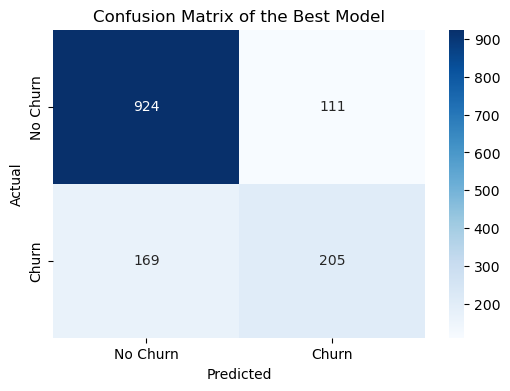

Classification Report of the best model:
              precision    recall  f1-score   support

    No Churn       0.85      0.89      0.87      1035
       Churn       0.65      0.55      0.59       374

    accuracy                           0.80      1409
   macro avg       0.75      0.72      0.73      1409
weighted avg       0.79      0.80      0.80      1409



In [16]:
#Evaluate the best model on the test set:
y_pred = best_model.predict(X_test_processed)

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix of the Best Model")
plt.show()

print("Classification Report of the best model:")
print(classification_report(
    y_test, y_pred, target_names=["No Churn", "Churn"]
))

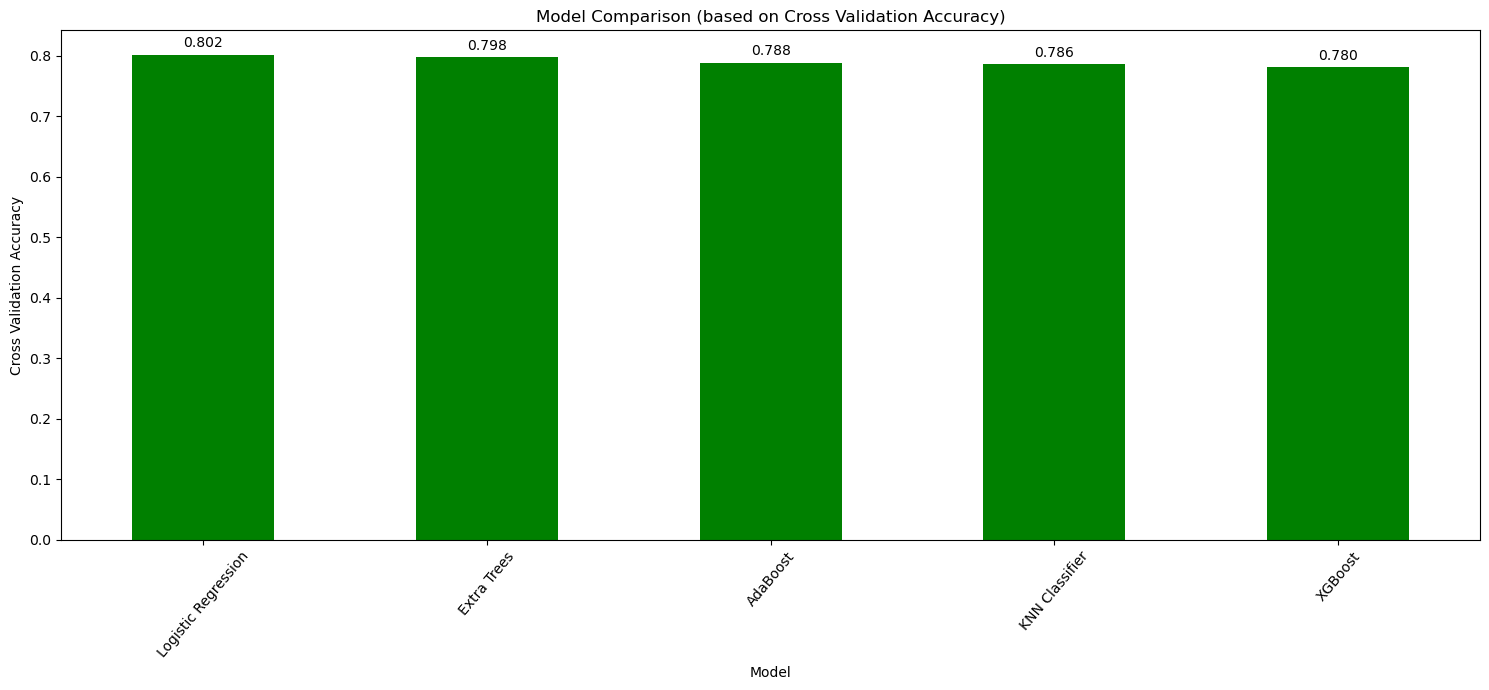

In [17]:
# Model comparison based on cross-validation accuracy
plt.figure(figsize=(15, 7))
ax = results_df.set_index("Model")["CV Accuracy"].plot(kind="bar", color="green")
ax.bar_label(ax.containers[0], fmt="%.3f", padding=3)
plt.title("Model Comparison (based on Cross Validation Accuracy)")
plt.xlabel("Model")
plt.ylabel("Cross Validation Accuracy")
plt.xticks(rotation=50)
plt.tight_layout()
plt.show()

In [18]:
# Save model and preprocessing objects together:
model_bundle = {
    "model": best_model,
    "model_name": best_model_name,
    "scaler": scaler,
    "encoder": encoder,
    "num_cols": num_cols,
    "cat_cols": cat_cols,
    "cat_feature_names": cat_feature_names.tolist(),
    "feature_cols": feature_cols
}

joblib.dump(model_bundle, "CustomerChurnPredictionModel.pkl")
print("Model and preprocessing objects saved successfully.")

Model and preprocessing objects saved successfully.
